In [12]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths


### Import Data

In [13]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/
#!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [14]:
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis.nc')
ds_t2m = xr.open_dataset('../temperature/ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')

In [15]:
lon = ds["lon"]
lat = ds["lat"]
times = ds["time"]

DAV_tracked = ds['DAV_tracked']
block_freq = ds['DAV_freq']
t2m = ds_t2m['t2m'][:,:,:]
stat_waves = ds['zg'].mean('time')/9.81 - ds['zg'].mean(('time','lon'))/9.81
zg = ds['zg'][:,:,:]/9.81

### Blocking frequency vs stationary waves

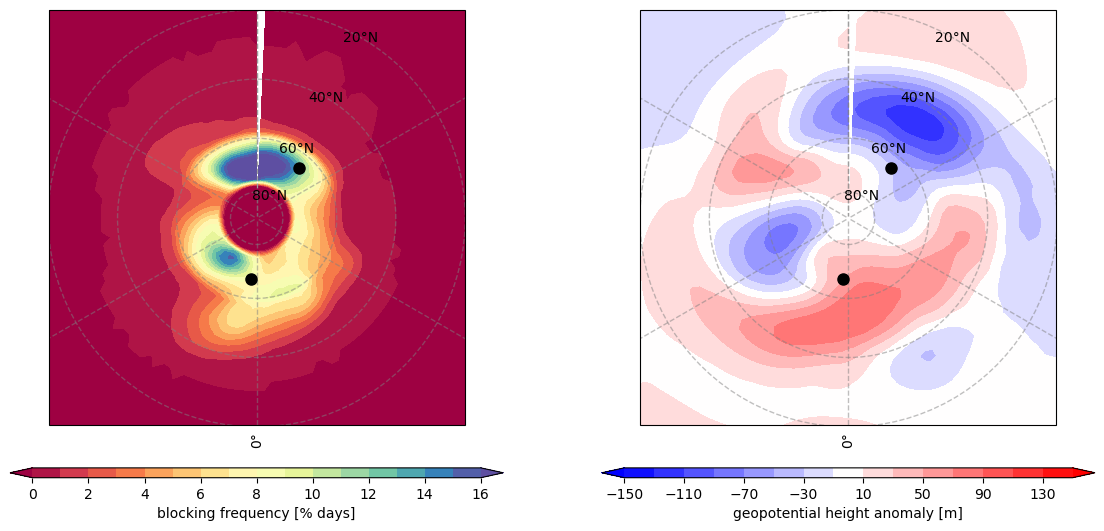

In [16]:
field = block_freq

fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(14,7),subplot_kw={'projection': ccrs.NorthPolarStereo()})
extent =[-180,180,20,90]


#PLOT 1

ax[0].set_extent(extent, ccrs.PlateCarree())
gl = ax[0].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

cont_range = np.arange(0,17,1)

gl.top_labels=False
gl.right_labels=False
cont = ax[0].contourf(lon,lat,field,
                   cont_range,
                   extent=[0,90,-180,180],
                   extend='both',
                   transform = ccrs.PlateCarree(),
                   cmap = "Spectral")
cbar = plt.colorbar(cont, orientation='horizontal',label="blocking frequency [% days]",pad=0.08, aspect=50)

ax[0].plot(-5, 67, marker='o', markersize=8, color='black', transform=ccrs.PlateCarree())

ax[0].plot(140, 65, marker='o', markersize=8, color='black', transform=ccrs.PlateCarree())

#PLOT 2

ax[1].set_extent(extent, ccrs.PlateCarree())
gl = ax[1].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

cont_range = np.arange(-150,160,20)

gl.top_labels=False
gl.right_labels=False
cont = ax[1].contourf(lon,lat,stat_waves,
                   cont_range,
                   extent=[0,90,-180,180],
                   extend='both',
                   transform = ccrs.PlateCarree(),
                   cmap = "bwr")
cbar = plt.colorbar(cont, orientation='horizontal',label="geopotential height anomaly [m]",pad=0.08, aspect=50)

ax[1].plot(-5, 67, marker='o', markersize=8, color='black', transform=ccrs.PlateCarree())

ax[1].plot(140, 65, marker='o', markersize=8, color='black', transform=ccrs.PlateCarree())



### Lagrangian analysis

In [19]:
#import dictionary
dic = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC_tyrlis.npy',allow_pickle=True) #original

#### Find box corners

In [20]:
def find_box_corners(plon,plat,lon_edge,lat_edge):
    lat_min, lat_max = int((plat-lat_edge/2)-20),int(plat+(lat_edge/2))
    lon_min, lon_max = int((plon-lon_edge/2)),int(plon+(lon_edge/2))
    if lon_max % 2.5 == 0:
        lon_max -= 0.0001
    if lat_max % 2.5 == 0:
        lat_max -= 0.0001
    return lat_min,lat_max,lon_min,lon_max

#### Anticyclonic Blocking

In [21]:
#SHIFT LIST
def shift_list(list):
    for i,el in enumerate(list):
        list[i] += 180
    return list

In [52]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -180, -150
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

In [53]:
#Create a list of labels
arr = DAV_tracked.values
labels = []
timings = []
min_pers = 3
for t,time in tqdm(enumerate(times)):
    if t > len(times.values)-5:
        break
    labels_of_the_day = np.unique(arr[t,mask_bool])
    for label in labels_of_the_day:
        check_cond = []
        for k in range(min_pers):
            check_cond.append(np.any(arr[t+k,mask_bool]==label))
        if label not in labels and np.all(check_cond) and label!=0:
            labels.append(label)
            timings.append(t)

30677it [00:20, 1523.45it/s]


In [54]:
areas = []
persistences = []
for label in labels:
    areas.append(np.mean(dic[label]['area']))
    persistences.append(dic[label]['persistence'])

Number of events: 2439


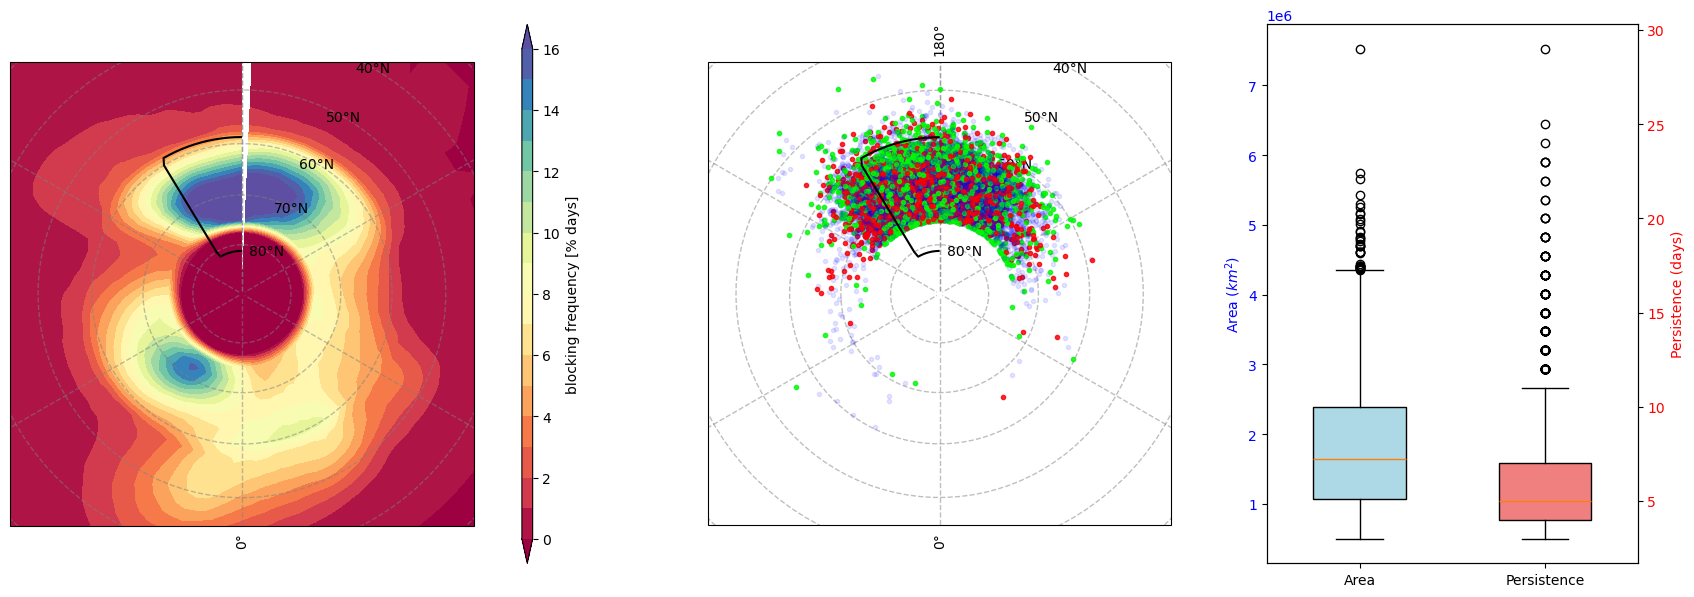

In [55]:
lon = ds["lon"]
lat = ds["lat"]
field = block_freq

datacrs = ccrs.PlateCarree()

fig = plt.figure(figsize=(21, 7))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.3, 1, 0.8])  # First column is twice as wide

# 3D Projection
ax1 = fig.add_subplot(gs[0], projection=ccrs.NorthPolarStereo())

extent =[-180,180,45,90]

#PLOT 1

ax1.set_extent(extent, ccrs.PlateCarree())
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

cont_range = np.arange(0,17,1)

gl.top_labels=False
gl.right_labels=False
cont = ax1.contourf(lon,lat,field,
                   cont_range,
                   extent=[0,90,-180,180],
                   extend='both',
                   transform = ccrs.PlateCarree(),
                   cmap = "Spectral")
cbar = plt.colorbar(cont, orientation='vertical',label="blocking frequency [% days]",pad=0.08, aspect=50)

BOX = ax1.contour(lon,lat,mask_xr,levels=[0.5,1.5],colors= 'black',transform=ccrs.PlateCarree())

#PLOT 2
ax2 = fig.add_subplot(gs[1], projection=ccrs.NorthPolarStereo())

ax2.set_extent(extent, ccrs.PlateCarree())
gl = ax2.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

for l,label in enumerate(labels):
    #print(label)
    #print(dics[j][label])
    for i in range(len(dic[label]['track'][1])):
        #print(el[1],el[0])
        cm = ax2.plot(dic[label]['track'][1][i],dic[label]['track'][0][i],'o', markersize=3,color='b',alpha=0.1,transform = ccrs.PlateCarree())
    #plot the ending center of mass position
    end = ax2.plot(dic[label]['track'][1][-1],dic[label]['track'][0][-1],'o', markersize=3,color='r',alpha=0.8,transform = ccrs.PlateCarree())
    #plot the starting center of mass position
    start = ax2.plot(dic[label]['track'][1][0],dic[label]['track'][0][0],'o', markersize=3,color='lime',alpha=0.8,transform = ccrs.PlateCarree())
    #text = ax2.text(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],str(label)  )
    # Create a rectangle patch

BOX = ax2.contour(lon,lat,mask_xr,levels=[0.5,1.5],colors= 'black',transform=ccrs.PlateCarree())

#PLOT 3

ax3 = fig.add_subplot(gs[2])

# Boxplot for first quantity (Primary y-axis)
box1 = ax3.boxplot(areas, positions=[1], widths=0.5, patch_artist=True, boxprops=dict(facecolor="lightblue"))
ax3.set_ylabel("Area ($km^2$)", color="blue")
ax3.tick_params(axis='y', labelcolor="blue")

ax4 = ax3.twinx()

# Boxplot for second quantity (Secondary y-axis)
box2 = ax4.boxplot(persistences, positions=[2], widths=0.5, patch_artist=True, boxprops=dict(facecolor="lightcoral"))
ax4.set_ylabel("Persistence (days)", color="red")
ax4.tick_params(axis='y', labelcolor="red")

# Set x-axis labels
ax4.set_xticks([1, 2])
ax4.set_xticklabels(["Area", "Persistence"])

print('Number of events: ' + str(len(labels)))

In [56]:
zg_rolled = zg.roll(lon=len(lon) // 2,roll_coords=True)
zg_rolled["lon"] = (zg_rolled["lon"] + 360) % 360  # Convert to 0-360
zg_rolled = zg_rolled.sortby("lon")  # Ensures lon increases from 0 to 360

zg_mean_rolled = zg_rolled.mean('time')

In [57]:
zgs = []
zgs_an = []
zg_mean = zg.mean('time')
count = 0
#populating the lists
for j,label in tqdm(enumerate(labels)):
    for t in range(dic[label]['time'],dic[label]['time']+dic[label]['persistence']):
        if np.any(arr[t,mask_bool] == label):
        #if np.any(arr[t,:,:] == label):
            dt = t-dic[label]['time']
            date = dic[label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
            lat_min,lat_max,lon_min,lon_max = find_box_corners(dic[label]['track'][1][dt],dic[label]['track'][0][dt],120,50)
            if lat_max > 90 or lat_min < 0:
                count += 1            
            elif lon_min <= -180 or lon_max > +180:
                if lon_min < 0:
                    lon_max += 360
                    lon_min += 360
                zgs.append(zg_rolled.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                zgs_an.append((zg_rolled.loc[date,:,:]-zg_mean_rolled).loc[lat_min:lat_max,lon_min:lon_max].values)
                while zgs[-1].shape[1] > 47:
                    zgs[-1] = np.delete(zgs[-1],1,axis = 1)
                    zgs_an[-1] = np.delete(zgs_an[-1],1,axis = 1)
                if zgs[-1].shape != (28,47):
                    print(lon_min,lon_max,lon_max-lon_min,zgs[-1].shape)
            else:
                zgs.append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                zgs_an.append((zg.loc[date,:,:]-zg_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                while zgs[-1].shape[1] > 47:
                    zgs[-1] = np.delete(zgs[-1],1,axis = 1)
                    zgs_an[-1] = np.delete(zgs_an[-1],1,axis = 1)
                if zgs[-1].shape != (28,47):
                    print(lon_min,lon_max,lon_max-lon_min,zgs[-1].shape)
zg_composite = sum(zgs)[:,:]/len(zgs)
zg_an_composite = sum(zgs_an)[:,:]/len(zgs_an)

2439it [00:08, 301.37it/s]


In [58]:
print(count)

9494


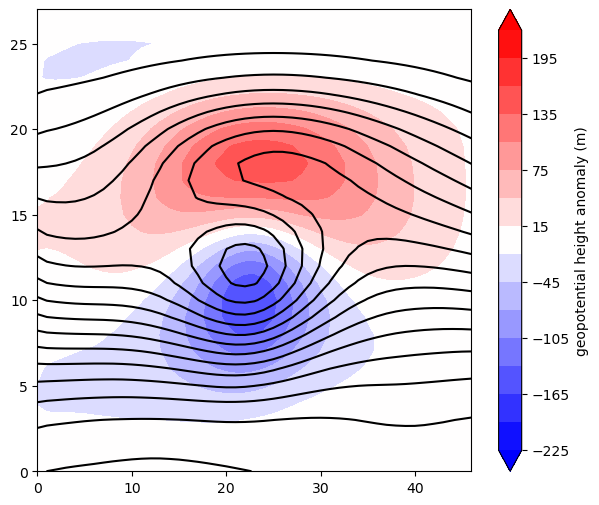

In [59]:
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(1, 1, width_ratios=[1])
levels = np.arange(4500,6500,40)
ax1 = fig.add_subplot(gs[0])
ax1.contour(zg_composite,levels,colors='black')
shad1_range = np.arange(-225,230,30)
shad1 = ax1.contourf(zg_an_composite,shad1_range,extend='both',cmap='bwr')
plt.colorbar(shad1,label = 'geopotential height anomaly (m)')